# T, U y D con `compute_tud`

H₂O de HITRAN2024 (HAPI, todos los isotopólogos) con su continuo, y la US Standard, en 714–1250 cm⁻¹ (8–14 µm).

`compute_tud` da la transmitancia T de la columna, la radiancia ascendente U en el tope y la descendente D en la
superficie. Con ellas, la radiancia en el tope es L = ε·B(T_skin)·T + U + (1 − ε)·T·D.

Paso de 0,01 cm⁻¹ para que corra rápido; las figuras van en canales IASI (gaussiana de FWHM 0,5 cm⁻¹).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import fftconvolve

from pylblrtm import compute_tud, from_hapi, planck, us_standard_atmosphere

NU_MIN, NU_MAX, PASO = 714.0, 1250.0, 0.01
KW = dict(step_cm1=PASO, voigt="humlicek", n_jobs=-1, h2o_continuum=True)

sd = from_hapi("H2O", NU_MIN - 25, NU_MAX + 25, iso_id="all")
perfil = us_standard_atmosphere(gases=["H2O"])
print(sd.n_lines, "líneas ·", perfil.n_layers, "capas")

HAPI version: 1.3.0.0
To get the most up-to-date version please check http://hitran.org/hapi
ATTENTION: Python versions of partition sums from TIPS-2021 are now available in HAPI code

           MIT license: Copyright 2021 HITRAN team, see more at http://hitran.org. 

           If you use HAPI in your research or software development,
           please cite it using the following reference:
           R.V. Kochanov, I.E. Gordon, L.S. Rothman, P. Wcislo, C. Hill, J.S. Wilzewski,
           HITRAN Application Programming Interface (HAPI): A comprehensive approach
           to working with spectroscopic data, J. Quant. Spectrosc. Radiat. Transfer 177, 15-30 (2016)
           DOI: 10.1016/j.jqsrt.2016.03.005

           ATTENTION: This is the core version of the HITRAN Application Programming Interface.
                      For more efficient implementation of the absorption coefficient routine, 
                      as well as for new profiles, parameters and other functional,
      


Data is fetched from http://hitran.org



BEGIN DOWNLOAD: H2O_iso1_689_1275


  65536 bytes written to C:\Users\PC\.pylblrtm\hitran_cache/H2O_iso1_689_1275.data
  65536 bytes written to C:\Users\PC\.pylblrtm\hitran_cache/H2O_iso1_689_1275.data


  65536 bytes written to C:\Users\PC\.pylblrtm\hitran_cache/H2O_iso1_689_1275.data
  65536 bytes written to C:\Users\PC\.pylblrtm\hitran_cache/H2O_iso1_689_1275.data
  65536 bytes written to C:\Users\PC\.pylblrtm\hitran_cache/H2O_iso1_689_1275.data
  65536 bytes written to C:\Users\PC\.pylblrtm\hitran_cache/H2O_iso1_689_1275.data
  65536 bytes written to C:\Users\PC\.pylblrtm\hitran_cache/H2O_iso1_689_1275.data
  65536 bytes written to C:\Users\PC\.pylblrtm\hitran_cache/H2O_iso1_689_1275.data
Header written to C:\Users\PC\.pylblrtm\hitran_cache/H2O_iso1_689_1275.header
END DOWNLOAD


...

BEGIN DOWNLOAD: H2O_iso6_689_1275
  65536 bytes written to C:\Users\PC\.pylblrtm\hitran_cache/H2O_iso6_689_1275.data
Header written to C:\Users\PC\.pylblrtm\hitran_cache/H2O_iso6_689_1275.header
END DOWNLOAD
                     Lines parsed: 211
PROCESSED
Using C:\Users\PC\.pylblrtm\hitran_cache

H2O_iso1_689_1275
                     Lines parsed: 2902
H2O_iso2_689_1275
                     Lines parsed: 847
H2O_iso3_689_1275
                     Lines parsed: 537
H2O_iso4_689_1275
                     Lines parsed: 2262
H2O_iso5_689_1275
                     Lines parsed: 419
H2O_iso6_689_1275
                     Lines parsed: 211



Data is fetched from http://hitran.org



BEGIN DOWNLOAD: H2O_iso7_689_1275
  65536 bytes written to C:\Users\PC\.pylblrtm\hitran_cache/H2O_iso7_689_1275.data


  65536 bytes written to C:\Users\PC\.pylblrtm\hitran_cache/H2O_iso7_689_1275.data
  65536 bytes written to C:\Users\PC\.pylblrtm\hitran_cache/H2O_iso7_689_1275.data
  65536 bytes written to C:\Users\PC\.pylblrtm\hitran_cache/H2O_iso7_689_1275.data
  65536 bytes written to C:\Users\PC\.pylblrtm\hitran_cache/H2O_iso7_689_1275.data
  65536 bytes written to C:\Users\PC\.pylblrtm\hitran_cache/H2O_iso7_689_1275.data
Header written to C:\Users\PC\.pylblrtm\hitran_cache/H2O_iso7_689_1275.header
END DOWNLOAD
                     Lines parsed: 2349
PROCESSED


9527 líneas · 20 capas


In [2]:
plt.rcParams.update({"font.family": "serif", "axes.linewidth": 1.5, "xtick.major.width": 1.2,
                     "ytick.major.width": 1.2, "figure.dpi": 110})


def iasi(y):
    """Canales IASI: gaussiana de FWHM 0,5 cm⁻¹, cada 0,25 cm⁻¹."""
    s = 0.5 / (2 * np.sqrt(2 * np.log(2))) / PASO
    k = np.exp(-0.5 * (np.arange(-int(6 * s), int(6 * s) + 1) / s) ** 2)
    k /= k.sum()
    return (fftconvolve(y, k, "same") / fftconvolve(np.ones_like(y), k, "same"))[::int(round(0.25 / PASO))]


def tb(nu, L):
    """Temperatura de brillo [K] de una radiancia en W/(cm² sr cm⁻¹)."""
    return 1.4387752 * nu / np.log1p(1.191042972e-12 * nu ** 3 / L)


def dbdt(nu, T):
    """dB/dT [W/(cm² sr cm⁻¹ K)], para pasar diferencias de radiancia a kelvin."""
    x = 1.4387752 * nu / T
    return planck(nu, T) * x / T / -np.expm1(-x)


def inversa(x):
    """µm ↔ cm⁻¹ para el eje de arriba."""
    with np.errstate(divide="ignore"):
        return 1e4 / np.asarray(x, float)


def ejes(titulo, ylabel):
    """Longitud de onda abajo, número de onda arriba."""
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.set_xlabel("longitud de onda [µm]")
    ax.set_ylabel(ylabel)
    ax.set_title(titulo)
    arriba = ax.secondary_xaxis("top", functions=(inversa, inversa))
    arriba.set_xlabel("número de onda [cm⁻¹]")
    return fig, ax

## 1. T, U y D

Un `compute_tud` por ángulo de visión, μ = cos θ. T y U dependen de μ; D no, porque la descendente usa la
difusividad (1,67 por defecto).

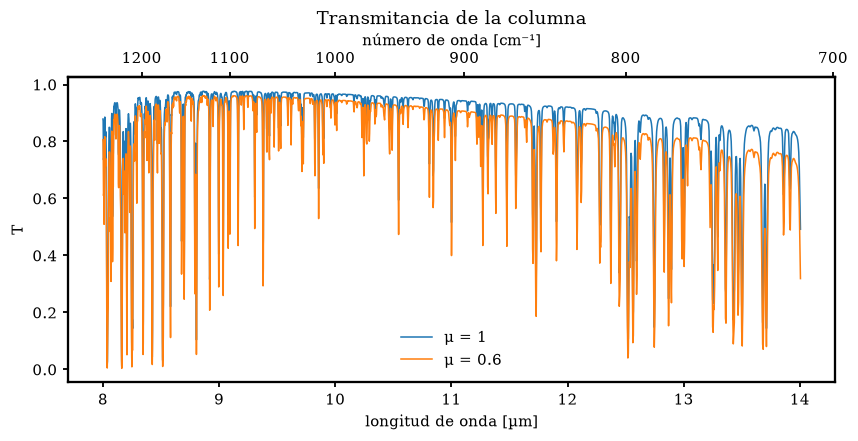

In [3]:
tud = {mu: compute_tud(sd, perfil, NU_MIN, NU_MAX, mu_view=mu, **KW) for mu in (1.0, 0.6)}
nu, T1, U1, D1 = tud[1.0]
nu_c = nu[::int(round(0.25 / PASO))]

fig, ax = ejes("Transmitancia de la columna", "T")
for mu, (_, T, U, D) in tud.items():
    ax.plot(1e4 / nu_c, iasi(T), lw=1, label=f"μ = {mu:g}")
ax.legend(frameon=False)
plt.show()

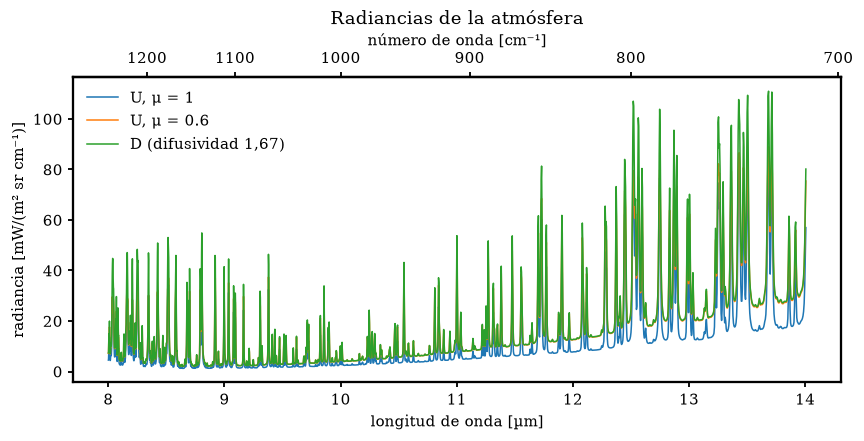

In [4]:
fig, ax = ejes("Radiancias de la atmósfera", "radiancia [mW/(m² sr cm⁻¹)]")
for mu, (_, T, U, D) in tud.items():
    ax.plot(1e4 / nu_c, iasi(U) * 1e7, lw=1, label=f"U, μ = {mu:g}")
ax.plot(1e4 / nu_c, iasi(D1) * 1e7, lw=1, label="D (difusividad 1,67)")
ax.legend(frameon=False)
plt.show()

## 2. Radiancia en el tope

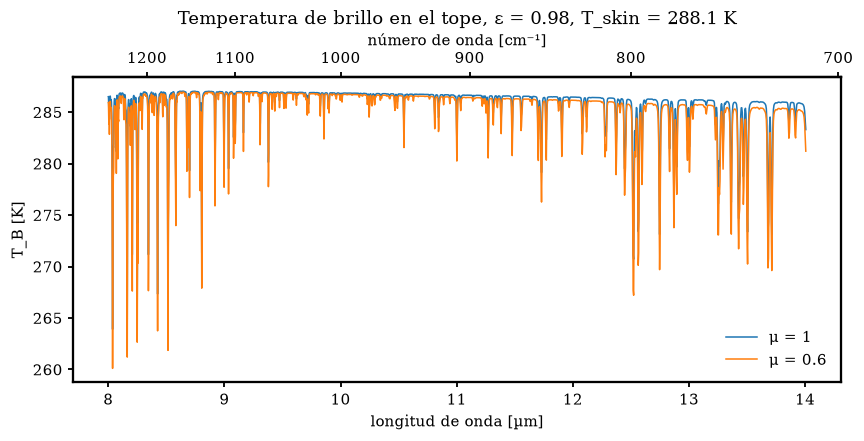

In [5]:
eps, T_skin = 0.98, float(perfil.temperature_k[-1])

fig, ax = ejes(f"Temperatura de brillo en el tope, ε = {eps}, T_skin = {T_skin:.1f} K", "T_B [K]")
for mu, (_, T, U, D) in tud.items():
    L = eps * planck(nu, T_skin) * T + U + (1 - eps) * T * D
    ax.plot(1e4 / nu_c, tb(nu_c, iasi(L)), lw=1, label=f"μ = {mu:g}")
ax.legend(frameon=False)
plt.show()

## 3. La B de cada capa

`layer_planck`: `"layer"` (B de la temperatura de la capa, la de las líneas; por defecto), `"density"`
(B de la temperatura ponderada por masa) o `"arithmetic"` (media de B en los dos niveles). Diferencia con
`"layer"`, en kelvin equivalentes a la T de superficie.

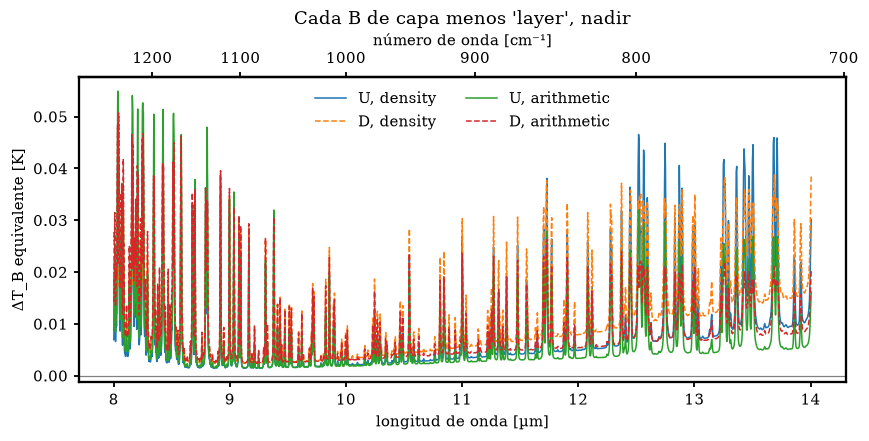

In [6]:
fig, ax = ejes("Cada B de capa menos 'layer', nadir", "ΔT_B equivalente [K]")
for opcion in ("density", "arithmetic"):
    _, _, U, D = compute_tud(sd, perfil, NU_MIN, NU_MAX, layer_planck=opcion, **KW)
    ax.plot(1e4 / nu_c, (iasi(U) - iasi(U1)) / dbdt(nu_c, T_skin), lw=1, label=f"U, {opcion}")
    ax.plot(1e4 / nu_c, (iasi(D) - iasi(D1)) / dbdt(nu_c, T_skin), lw=1, ls="--", label=f"D, {opcion}")
ax.axhline(0, color="0.5", lw=0.8)
ax.legend(frameon=False, ncol=2)
plt.show()